# Canopy height from GEDI lidar footprints (R)

**Question.** How tall is the forest around the Pando aspen stand, according to the laser footprints of NASA's GEDI instrument, and which footprints can we trust?

By the end of this lesson you will have a map and a chart like these, made from quality-screened GEDI footprints, and a file of footprints you can open in any GIS:

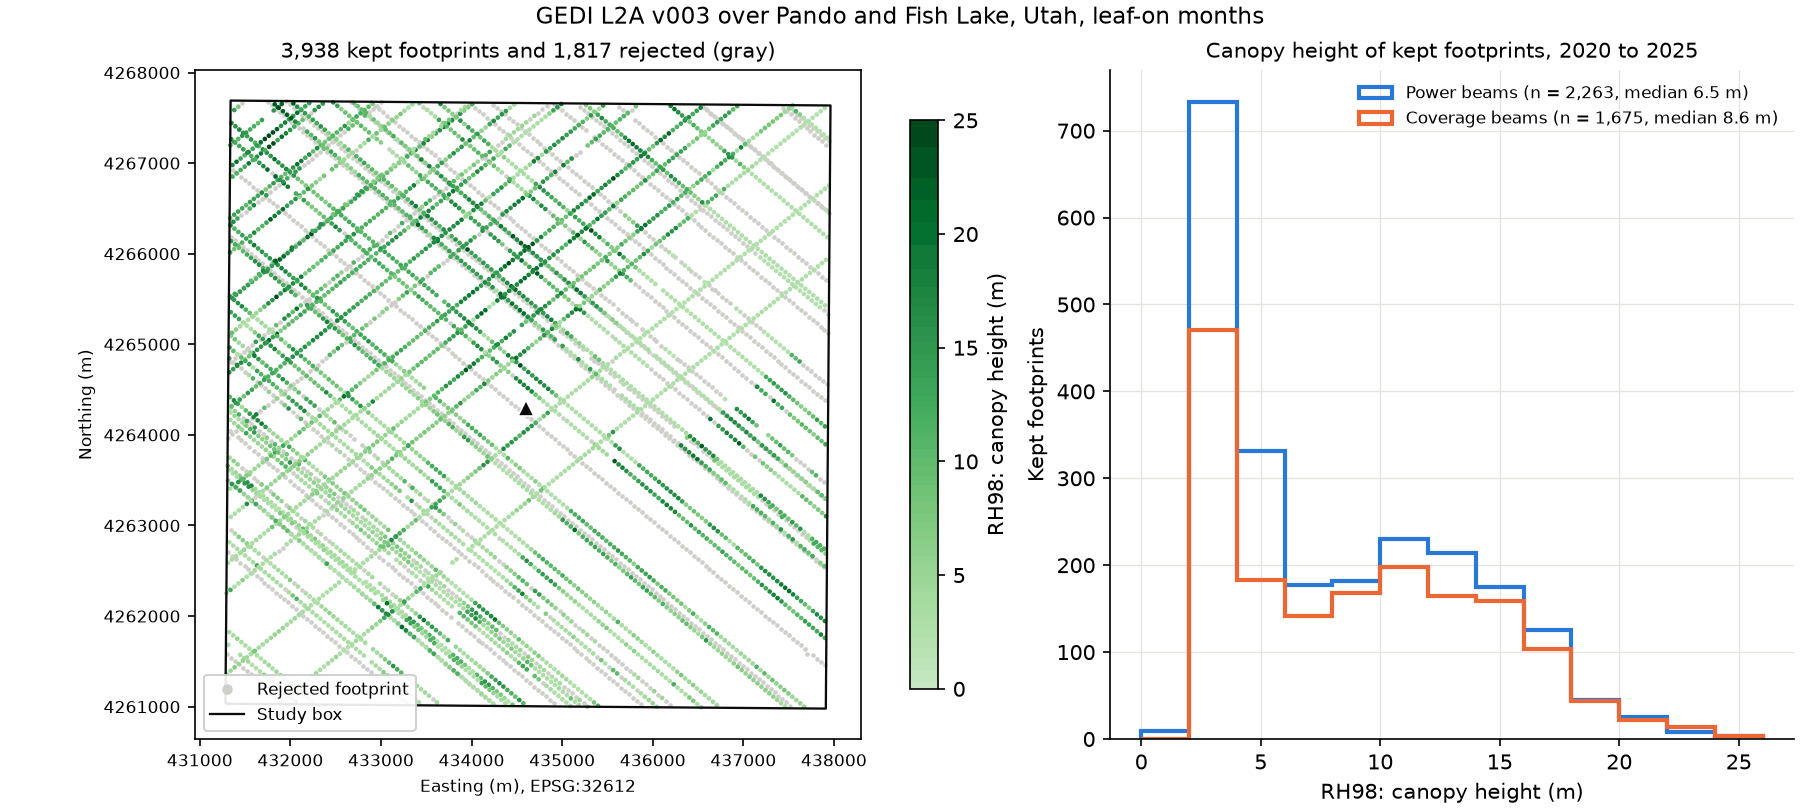

**You will learn to**

1. find GEDI data through NASA's catalog web interface and see why downloading whole files is impractical for a small study area;
2. send a request to NASA's **Harmony** service that cuts out only your area and variables, wait for the job, and download the result;
3. read GEDI's HDF5 files, screen footprints with the quality flags, and map canopy height as the samples it really is.

This is the R version of the lesson. The [Python version](gedi-canopy-height-python.ipynb) follows the same steps and produces the same result. Python has a ready-made package for Harmony; in R we talk to Harmony's web interface directly, which shows what such packages do behind the scenes.

## Before starting

- **Setup.** Run the [R getting-started notebook](../getting-started/getting-started-r.ipynb) first and choose the **R 4.5 (Trees from Space)** kernel. You need the Trees from Space R environment (created or updated on or after 2026-11-04, so that it includes `httr2` and `hdf5r`) and an Earthdata Login stored in `~/.netrc` ([guide](../../docs/getting-started/earthdata-login.md)).
- **CHPC.** Run the getting-started notebook in the same kind of OnDemand session first. If it reports that the session can reach NASA, run this lesson as it is. If not, fetch the data with a short transfer job, after which the whole notebook runs offline from the cache ([CHPC guide](../../docs/getting-started/chpc.md)).
- **Data volume.** A few megabytes of subset files. The same granules downloaded whole would be about 34 GB. If you already ran the Python version, this notebook reuses its subset files and sends nothing to Harmony.
- **Time.** About 25 minutes of reading and running, plus the time NASA's Harmony service takes to process the request (typically a few minutes; it runs on NASA's computers, not yours). Reruns take seconds.
- **Related lessons.** The [HLS](../hls-vegetation-map/) and [Sentinel-2](../sentinel2-stac/) lessons map the same area from above. This lesson can be done on its own.
- **Tested environments.** See the [lesson README](README.md). The R version has not been tested in Google Colab.

## The data in brief

**GEDI** (Global Ecosystem Dynamics Investigation) is a laser instrument (a **lidar**) on the International Space Station. It fires short laser pulses at the ground and records the returning light as a **waveform**: light reflected by the top of the canopy arrives first, light from lower branches later, and light from the ground last. Each pulse lights a circle on the ground about 25 m across, called a **footprint**.

GEDI has eight beam tracks. Four are **power beams** with full laser energy and four are **coverage beams** with less energy, which penetrate dense canopy less reliably. Along each track, footprints are about 60 m apart, and neighboring tracks are about 600 m apart. GEDI therefore **samples** the forest; it does not image it wall to wall. Its orbit covers the Earth between about 52° north and south.

The **Level 2A** product turns each waveform into **relative height (RH) metrics**: RH98 is the height above the ground at which 98% of the returned energy has arrived. It is a robust stand-in for canopy top height, in meters. This lesson uses **version 3** (`GEDI02_A` v003), which improved the geolocation and the quality flags.

**Limits to keep in mind.** On steep slopes the ground return spreads out, which can bias RH metrics. Each footprint's position is known to within about 10 m. Coverage beams can miss the ground under dense canopy. A footprint is a 25 m sample, so a map of footprints is not a map of the whole forest, and interpolating between them does not create new information.

## Settings

Everything you might change is in the next cell. Coordinates are longitude and latitude in decimal degrees (WGS84), in the order **west, south, east, north**. Dates use the format `"YYYY-MM-DD"`. If you run this notebook as a batch job, the job uses the values saved in this cell.

In [ ]:
# Study area: a box of longitude/latitude in degrees, ordered (west, south, east, north).
SITE_ID <- "pando"
SITE_NAME <- "Pando and Fish Lake, Utah"
BBOX <- c(-111.788, 38.495, -111.712, 38.555)

# Search window: the whole GEDI record so far. Only leaf-on months are kept.
START_DATE <- "2019-04-01"
END_DATE <- "2025-12-31"
LEAF_ON_MONTHS <- c(6, 7, 8, 9)

# Product and version.
SHORT_NAME <- "GEDI02_A"
VERSION <- "003"

# Request limit: the most granules to search for (at most 2000).
MAX_GRANULES <- 100

# Relative-height percentile used as canopy height (RH98).
RH_PERCENTILE <- 98

# Quality screening (see section 4).
POWER_BEAMS_ONLY <- FALSE
NIGHT_ONLY <- FALSE

# Stop waiting for NASA's Harmony service after this many minutes (the job keeps
# running at NASA; rerunning the notebook later picks it up again).
HARMONY_WAIT_MINUTES <- 20

## Setup

The next cell loads the packages this lesson uses and sets up the folders for cached data and results. **httr2** sends requests to web interfaces (here, NASA's catalog and Harmony), **hdf5r** reads HDF5 files, **sf** handles points and map projections, and **jsonlite** reads and writes JSON.

In [ ]:
# httr2 and hdf5r joined the project environment on 2026-11-04.
missing <- c("httr2", "hdf5r")[!vapply(c("httr2", "hdf5r"), requireNamespace, logical(1), quietly = TRUE)]
if (length(missing) > 0) {
  stop("This environment lacks ", paste(missing, collapse = ", "), ". From the repository folder, run ",
       "`mamba env update -p <prefix>/tfs-r -f environments/r-base.yml` (on CHPC, after ",
       "`module load miniforge3`), then restart the kernel.")
}
suppressPackageStartupMessages({
  library(httr2)
  library(hdf5r)
  library(sf)
  library(jsonlite)
})
options(repr.plot.width = 12, repr.plot.height = 5.4, repr.plot.res = 100)
RUN_STARTED <- Sys.time()

find_repo_root <- function(start = getwd()) {
  # Walk up from `start` to the folder holding the .tfs-root marker file.
  folder <- normalizePath(start)
  repeat {
    if (file.exists(file.path(folder, ".tfs-root"))) return(folder)
    parent <- dirname(folder)
    if (parent == folder) return(NULL)
    folder <- parent
  }
}

env_or <- function(name, default) {
  value <- Sys.getenv(name)
  if (nzchar(value)) value else default
}

REPO_ROOT <- find_repo_root()
BASE_DIR <- if (is.null(REPO_ROOT)) getwd() else REPO_ROOT
CACHE_DIR <- env_or("TFS_CACHE_DIR", file.path(BASE_DIR, "cache"))
OUTPUT_DIR <- env_or("TFS_OUTPUT_DIR", file.path(BASE_DIR, "outputs"))

# One cache folder per study box, named by its coordinates, so the Python lesson finds the same files.
box_name <- paste(sprintf("%.4f", BBOX), collapse = "_")
SITE_CACHE <- file.path(CACHE_DIR, "gedi", paste0(SITE_ID, "_", box_name))
LESSON_OUTPUT <- file.path(OUTPUT_DIR, "gedi-canopy-height", "r")
dir.create(SITE_CACHE, recursive = TRUE, showWarnings = FALSE)
dir.create(LESSON_OUTPUT, recursive = TRUE, showWarnings = FALSE)
cat("Cache:  ", SITE_CACHE, "\n")
cat("Results:", LESSON_OUTPUT, "\n")

### Helpers for reading data once

As in the earlier lessons, everything downloaded goes into the cache and is reused, so the notebook also runs offline once the cache is filled. The Harmony job number is saved too: if the notebook stops while NASA is still processing, a rerun picks up the same job instead of submitting a duplicate.

The `earthdata()` helper prepares a web request for NASA's services. It tells **libcurl**, the library that httr2 uses to send requests, three things: to read your username and password from `~/.netrc`, to send them to NASA's login server straight away (*basic* authentication; otherwise libcurl waits for a challenge that this server never sends), and to keep the login cookies NASA hands back in a private file, so later requests are recognized without logging in again. Your password is never printed or saved in the notebook.

In [ ]:
NETRC_PATH <- env_or("NETRC", path.expand("~/.netrc"))
cookie_dir <- path.expand("~/.cache/trees-from-space")
dir.create(cookie_dir, recursive = TRUE, showWarnings = FALSE)
Sys.chmod(cookie_dir, mode = "0700")
cookie_file <- file.path(cookie_dir, "earthdata-cookies.txt")
CMR_URL <- "https://cmr.earthdata.nasa.gov/search"
HARMONY_URL <- "https://harmony.earthdata.nasa.gov"

earthdata <- function(req) {
  # Add Earthdata Login credentials, cookies, retries, and a time limit to a request.
  req |>
    req_options(netrc = 1L, netrc_file = NETRC_PATH, httpauth = 1L) |>
    req_cookie_preserve(cookie_file) |>
    req_retry(max_tries = 3) |>
    req_timeout(120)
}

network_available <- function(host = "cmr.earthdata.nasa.gov", timeout_s = 5) {
  # Return TRUE if an HTTPS request to NASA's catalog succeeds.
  if (Sys.getenv("TFS_OFFLINE") == "1") return(FALSE)  # lets you test the offline route
  handle <- curl::new_handle(connecttimeout = timeout_s, timeout = 3 * timeout_s, nobody = TRUE)
  tryCatch({
    curl::curl_fetch_memory(paste0("https://", host, "/search/health"), handle = handle)
    TRUE
  }, error = function(e) FALSE)
}

offline_message <- function(missing) {
  paste0(
    "This machine cannot reach NASA, and the cache does not yet hold ", basename(missing), ". ",
    "Run the notebook once on a machine with internet access (on CHPC, use a transfer ",
    "job; see docs/getting-started/chpc.md), then rerun it here."
  )
}

write_atomically <- function(path, write) {
  # Call write(temporary_path), then rename the result to `path`. The temporary name
  # keeps the file type at the end, e.g. "x.part.gpkg".
  temporary <- sub("(\\.[^.]+)$", ".part\\1", path)
  write(temporary)
  file.rename(temporary, path)
}

login_state <- new.env()
login_state$done <- FALSE

ensure_login <- function() {
  # Log in to Earthdata once, just before the first request that needs it.
  if (login_state$done) return(invisible(TRUE))
  has_entry <- file.exists(NETRC_PATH) &&
    any(grepl("urs.earthdata.nasa.gov", readLines(NETRC_PATH, warn = FALSE), fixed = TRUE))
  if (!has_entry) {
    stop("No Earthdata credentials in ", NETRC_PATH, ". See docs/getting-started/earthdata-login.md.")
  }
  # Asking Harmony for our list of jobs sends us through NASA's login server, which checks
  # the credentials and returns a session cookie that the later requests reuse.
  resp <- request(paste0(HARMONY_URL, "/jobs")) |>
    earthdata() |>
    req_url_query(limit = 1) |>
    req_error(is_error = function(resp) FALSE) |>
    req_perform()
  if (resp_status(resp) != 200 || !grepl("json", resp_content_type(resp))) {
    stop("NASA did not accept the credentials in ", NETRC_PATH, " (HTTP ", resp_status(resp), ").")
  }
  login_state$done <- TRUE
  invisible(TRUE)
}

ONLINE <- network_available()
cat(if (ONLINE) "Network: online\n" else "Network: offline (only cached data can be used)\n")

## 1. Find GEDI granules

A GEDI **granule** covers one quarter of an orbit of the space station, about 10,000 km of ground track. NASA's catalog, the **Common Metadata Repository (CMR)**, has a web interface: we send it a web address with our search terms as **query parameters** (the `name=value` pairs after the `?`), and it answers in JSON. The search below asks for every granule whose track crosses our box during our dates. The catalog needs no login. We then keep the leaf-on months, when deciduous trees such as aspen carry their leaves.

In [ ]:
load_or_search <- function() {
  # Return granule records for the box, from the cache when possible.
  path <- file.path(SITE_CACHE, sprintf("search_%s_v%s_%s_%s_max%d.json",
                                        SHORT_NAME, VERSION, START_DATE, END_DATE, MAX_GRANULES))
  if (file.exists(path)) {
    cat(basename(path), "(cached)\n")
    return(as.data.frame(read_json(path, simplifyVector = TRUE)))
  }
  if (!ONLINE) stop(offline_message(path))
  resp <- request(paste0(CMR_URL, "/granules.umm_json")) |>
    req_url_query(short_name = SHORT_NAME, version = VERSION,
                  bounding_box = paste(BBOX, collapse = ","),
                  temporal = paste0(START_DATE, "T00:00:00Z,", END_DATE, "T23:59:59Z"),
                  page_size = MAX_GRANULES) |>
    req_retry(max_tries = 3) |>
    req_perform()
  items <- resp_body_json(resp)$items
  records <- data.frame(
    granule_id = vapply(items, function(g) g$umm$GranuleUR, ""),
    concept_id = vapply(items, function(g) g$meta[["concept-id"]], ""),
    collection_concept_id = vapply(items, function(g) g$meta[["collection-concept-id"]], ""),
    start_utc = vapply(items, function(g) g$umm$TemporalExtent$RangeDateTime$BeginningDateTime, ""),
    size_gb = vapply(items, function(g) {
      files <- g$umm$DataGranule$ArchiveAndDistributionInformation
      round(sum(vapply(files, function(f) as.numeric(f$SizeInBytes %||% 0), 0)) / 1e9, 2)
    }, 0)
  )
  write_atomically(path, function(tmp) write_json(records, tmp, pretty = TRUE, digits = NA))
  cat(nrow(records), "granules found (searched NASA's catalog)\n")
  records
}

granules <- load_or_search()
if (nrow(granules) == 0) {
  stop("No GEDI granules matched. Check that BBOX is ordered (west, south, east, north), ",
       "that it lies between 52 degrees north and south, and that the dates fall within ",
       "the GEDI record (from April 2019).")
}
start_time <- as.POSIXct(granules$start_utc, format = "%Y-%m-%dT%H:%M:%OS", tz = "UTC")
granules$date <- as.Date(start_time)
granules <- granules[as.integer(format(start_time, "%m")) %in% LEAF_ON_MONTHS, ]
granules <- granules[order(granules$start_utc), ]
rownames(granules) <- NULL
cat(sprintf("%d leaf-on granules; downloading them whole would transfer %.1f GB.\n",
            nrow(granules), sum(granules$size_gb)))
granules[, c("granule_id", "date", "size_gb")]

Each granule is about 2 GB, yet only a few hundred of its millions of footprints fall inside our box. Downloading whole granules would move tens of gigabytes to use a few megabytes.

## 2. Ask Harmony for a subset

**Harmony** is a NASA service that processes data where it is stored, in the cloud, and returns only what you ask for. This lesson asks it to:

- cut each granule to the footprints inside our box (a *spatial subset*), and
- keep only the variables we need (a *variable subset*).

GEDI files are organized as one group per beam (`BEAM0000` to `BEAM1011`), each holding the same variables, so the request lists each variable for each beam. Harmony works **asynchronously**: we submit a request and receive a job number, Harmony processes the granules on NASA's computers, and we download the results when the job finishes.

The request is a **form**, like one you would fill in on a web page, sent to an address that names the collection. Each field is a name and a value, and some names repeat:

| Field | Value | Meaning |
| --- | --- | --- |
| `subset` | `lat(south:north)`, `lon(west:east)` | the box |
| `granuleId` | the granules' catalog IDs, separated by commas | which granules to process |
| `variable` | one field per variable, such as `/BEAM0101/rh` | which variables to keep |
| `forceAsync` | `true` | always run as a job, even for a small request |
| `label` | `trees-from-space` | a tag that helps you find the job in Harmony's job list |

The next cell builds the form without sending it.

In [ ]:
POWER_BEAMS <- c("BEAM0101", "BEAM0110", "BEAM1000", "BEAM1011")
COVERAGE_BEAMS <- c("BEAM0000", "BEAM0001", "BEAM0010", "BEAM0011")
FIELDS <- c(
  "lat_lowestmode", "lon_lowestmode", "rh", "l2a_quality_flag_rel3", "degrade_flag",
  "sensitivity", "solar_elevation", "delta_time", "shot_number",
  "land_cover_data/leaf_off_flag", "land_cover_data/landsat_treecover"
)
variables <- unlist(lapply(c(POWER_BEAMS, COVERAGE_BEAMS), function(beam) paste0("/", beam, "/", FIELDS)))

submit_url <- paste0(HARMONY_URL, "/", granules$collection_concept_id[1],
                     "/ogc-api-coverages/1.0.0/collections/parameter_vars/coverage/rangeset")
form <- c(
  list(subset = sprintf("lat(%s:%s)", BBOX[2], BBOX[4]),
       subset = sprintf("lon(%s:%s)", BBOX[1], BBOX[3]),
       granuleId = paste(granules$concept_id, collapse = ","),
       forceAsync = "true",
       label = "trees-from-space"),
  setNames(as.list(variables), rep("variable", length(variables)))
)

# A short name for this exact request, so a rerun finds its job and its results. It is
# built from the same text as in the Python lesson, so the two lessons share the cache.
key_text <- paste0(
  "[[", paste0('"', sort(granules$concept_id, method = "radix"), '"', collapse = ", "), "], ",
  "[", paste(BBOX, collapse = ", "), "], ",
  "[", paste0('"', variables, '"', collapse = ", "), "]]"
)
request_key <- substr(as.character(openssl::sha1(key_text)), 1, 10)
JOB_FILE <- file.path(SITE_CACHE, paste0("harmony_", request_key, "_job.json"))
SUBSET_DIR <- file.path(SITE_CACHE, paste0("harmony_", request_key))
cat(sprintf("Request: %d granules, %d variables, box (%s)\n", nrow(granules), length(variables),
            paste(BBOX, collapse = ", ")))
cat("Form fields:", paste(head(names(form), 6), collapse = ", "), "... (", length(form), "in all)\n")

The next cell submits the form, waits for Harmony to finish, and downloads the subset files into the cache. Everything happens only once:

- if the subset files are already in the cache, nothing is sent;
- if a job was already submitted, the cell reuses its job number instead of submitting again;
- the files are downloaded into a temporary folder that is renamed only when every file has arrived.

Harmony answers each request with JSON. The answer to the form describes the new job, including its `jobID`. Asking for `/jobs/<jobID>` returns the job's `status` and `progress` (percent done), and, once it has finished, a list of `links` to the result files. While you wait, the cell prints the progress every time it changes. Processing usually takes one to a few minutes, but a busy service can take longer. If the job is not done after `HARMONY_WAIT_MINUTES`, the cell stops waiting and tells you so; the job keeps running at NASA, and rerunning the cell later picks it up.

In [ ]:
FINISHED <- c("successful", "complete_with_errors", "failed", "canceled")

harmony_json <- function(req) {
  # Send a request to Harmony and return its JSON answer, with Harmony's own error message on failure.
  req |>
    earthdata() |>
    req_error(body = function(resp) tryCatch(resp_body_json(resp)$description, error = function(e) NULL)) |>
    req_perform() |>
    resp_body_json()
}

job_status <- function(job_id) harmony_json(request(paste0(HARMONY_URL, "/jobs/", job_id)))

wait_for_job <- function(job_id) {
  # Poll the job until it finishes, printing progress, or stop after the time limit.
  deadline <- Sys.time() + 60 * HARMONY_WAIT_MINUTES
  last_progress <- -1
  repeat {
    status <- job_status(job_id)
    if (status$progress != last_progress) {
      cat(sprintf("  %s  %s: %s%% done\n", format(Sys.time(), "%H:%M:%S"), status$status, status$progress))
      last_progress <- status$progress
    }
    if (status$status %in% FINISHED) return(status)
    if (Sys.time() > deadline) {
      stop("Harmony job ", job_id, " is still ", status$status, " (", status$progress, "% done) after ",
           HARMONY_WAIT_MINUTES, " minutes. It keeps running at NASA: rerun this cell later to ",
           "pick it up, or raise HARMONY_WAIT_MINUTES.")
    }
    Sys.sleep(10)
  }
}

result_links <- function(job_id) {
  # Collect the links to every result file; long lists come in pages linked by "next".
  url <- paste0(HARMONY_URL, "/jobs/", job_id)
  hrefs <- character(0)
  while (!is.null(url)) {
    page <- harmony_json(request(url))
    links <- page$links
    hrefs <- c(hrefs, vapply(Filter(function(l) l$rel == "data", links), function(l) l$href, ""))
    next_page <- Filter(function(l) l$rel == "next", links)
    url <- if (length(next_page) > 0) next_page[[1]]$href else NULL
  }
  hrefs
}

load_or_request_subset <- function() {
  # Return the subset files, submitting a Harmony job only if needed.
  if (dir.exists(SUBSET_DIR)) {
    cat(basename(SUBSET_DIR), "/ (cached)\n", sep = "")
    return(sort(list.files(SUBSET_DIR, pattern = "\\.h5$", full.names = TRUE), method = "radix"))
  }
  if (!ONLINE) stop(offline_message(SUBSET_DIR))
  ensure_login()
  job_id <- NULL
  if (file.exists(JOB_FILE)) {
    job_id <- read_json(JOB_FILE)$job_id
    status <- job_status(job_id)$status
    if (status %in% c("failed", "canceled")) {
      cat("Earlier job ", job_id, " ended as '", status, "'; submitting a new one.\n", sep = "")
      job_id <- NULL
    } else {
      cat("Reusing Harmony job ", job_id, " (", status, ")\n", sep = "")
    }
  }
  if (is.null(job_id)) {
    job <- harmony_json(request(submit_url) |> req_body_multipart(!!!form))
    job_id <- job$jobID
    record <- list(job_id = job_id, submitted_utc = format(Sys.time(), "%Y-%m-%dT%H:%M:%S+00:00", tz = "UTC"))
    write_atomically(JOB_FILE, function(tmp) write_json(record, tmp, auto_unbox = TRUE))
    cat("Submitted Harmony job", job_id, "\n")
  }
  started <- Sys.time()
  status <- wait_for_job(job_id)
  cat(sprintf("Harmony job %s after %.0f s: %s\n", status$status,
              as.numeric(Sys.time() - started, units = "secs"), status$message))
  if (!status$status %in% c("successful", "complete_with_errors")) {
    stop("Harmony job ", job_id, " ended as '", status$status, "'. Rerun this cell to resubmit.")
  }
  temporary <- paste0(SUBSET_DIR, ".part")
  unlink(temporary, recursive = TRUE)
  dir.create(temporary)
  for (href in result_links(job_id)) {
    # Name each file "<work item>_<file name>", the folder and file at the end of its link.
    parts <- strsplit(href, "/", fixed = TRUE)[[1]]
    name <- paste0(parts[length(parts) - 1], "_", parts[length(parts)])
    request(href) |> earthdata() |> req_perform(path = file.path(temporary, name))
  }
  file.rename(temporary, SUBSET_DIR)
  files <- sort(list.files(SUBSET_DIR, pattern = "\\.h5$", full.names = TRUE), method = "radix")
  cat("Downloaded", length(files), "subset files\n")
  files
}

subset_files <- load_or_request_subset()
subset_mb <- sum(file.size(subset_files)) / 1e6
cat(sprintf("%d subset files, %.1f MB in all\n", length(subset_files), subset_mb))

A job often ends as *successful with warnings*, and there may be fewer subset files than granules. The catalog finds granules by a rough outline of each orbit segment, so some granules match the box without any footprint actually falling inside it. Harmony reports a warning for each of those and returns no file.

## 3. Read the footprints

GEDI files are **HDF5**: one file holds many arrays arranged in groups, like folders. **hdf5r** opens the file, and `file[["BEAM0101/rh"]]$read()` reads one array by its path. Every array in a beam group has one value per footprint, in the same order, so the arrays line up as the columns of a table.

Three details matter when reading them:

- `rh` holds 101 values per footprint (RH0 to RH100). hdf5r returns it with **one column per footprint** and one row per percentile, the reverse of how the file describes it (R stores matrices column by column), so RH98 is row 99: `rh[RH_PERCENTILE + 1, ]`.
- `shot_number`, the footprint's unique ID, is a very large whole number. R's ordinary numbers cannot hold it exactly, so hdf5r returns it as a 64-bit integer (from the **bit64** package), and we keep it as text, because spreadsheets and some file formats would round it.
- `delta_time` counts seconds since the start of 2018, which we turn into a date.

In [ ]:
GEDI_EPOCH <- as.POSIXct("2018-01-01 00:00:00", tz = "UTC")
RH_COLUMN <- paste0("rh", RH_PERCENTILE, "_m")

read_footprints <- function(path) {
  # Read one subset file into a table with one row per footprint.
  subset <- H5File$new(path, mode = "r")
  on.exit(subset$close_all())
  # Harmony names files "<work item>_<granule>_subsetted.h5"; keep the granule.
  name <- basename(path)
  granule <- sub("_subsetted.*$", "", substring(name, regexpr(SHORT_NAME, name, fixed = TRUE)))
  tables <- list()
  for (beam in c(POWER_BEAMS, COVERAGE_BEAMS)) {
    if (!subset$exists(beam) || !subset[[beam]]$exists("lat_lowestmode")) next
    group <- subset[[beam]]
    read <- function(variable) group[[variable]]$read()
    lat <- read("lat_lowestmode")
    if (length(lat) == 0) next
    rh <- matrix(read("rh"), nrow = 101)  # one column per footprint
    table <- data.frame(
      granule = granule,
      beam = beam,
      beam_type = if (beam %in% POWER_BEAMS) "power" else "coverage",
      shot_number = as.character(read("shot_number")),
      time_utc = GEDI_EPOCH + read("delta_time"),
      lon = read("lon_lowestmode"),
      lat = lat,
      rh = rh[RH_PERCENTILE + 1, ],
      quality_flag = read("l2a_quality_flag_rel3"),
      degrade_flag = read("degrade_flag"),
      sensitivity = read("sensitivity"),
      solar_elevation_deg = read("solar_elevation"),
      leaf_off_flag = read("land_cover_data/leaf_off_flag"),
      landsat_treecover_pct = read("land_cover_data/landsat_treecover")
    )
    names(table)[names(table) == "rh"] <- RH_COLUMN
    tables[[beam]] <- table
  }
  do.call(rbind, unname(tables))
}

footprints <- do.call(rbind, lapply(subset_files, read_footprints))
west <- BBOX[1]; south <- BBOX[2]; east <- BBOX[3]; north <- BBOX[4]
inside <- footprints$lon >= west & footprints$lon <= east & footprints$lat >= south & footprints$lat <= north
footprints <- footprints[inside, ]
rownames(footprints) <- NULL
if (nrow(footprints) == 0) stop("No GEDI footprints fell inside the box. Try a larger box or a longer date window.")
cat(sprintf("%s footprints inside the box, from %d granules\n",
            format(nrow(footprints), big.mark = ","), length(unique(footprints$granule))))
head(footprints)

## 4. Screen the footprints

Not every footprint measures the canopy well. Clouds can block the laser, the instrument sometimes operates in a degraded state, and weak returns can miss the ground. GEDI version 3 provides a summary **quality flag** for this (`l2a_quality_flag_rel3`): a footprint gets 1 only if its waveform passes checks of energy, signal strength, sensitivity (at least 0.95 over land), and agreement with a terrain model. We also drop footprints taken while the instrument was **degraded** (`degrade_flag` not 0).

The user guide adds two recommendations for dense forest: prefer **power beams**, and prefer **night** acquisitions (solar elevation below 0), when sunlight adds no background noise. The settings `POWER_BEAMS_ONLY` and `NIGHT_ONLY` apply them. They are off by default so that you can compare the beams below.

In [ ]:
keep <- footprints$quality_flag == 1 & footprints$degrade_flag == 0
steps <- list(
  "All footprints in the box" = rep(TRUE, nrow(footprints)),
  "Quality flag = 1" = footprints$quality_flag == 1,
  "... and not degraded" = keep
)
if (POWER_BEAMS_ONLY) {
  keep <- keep & footprints$beam_type == "power"
  steps[["... and power beam"]] <- keep
}
if (NIGHT_ONLY) {
  keep <- keep & footprints$solar_elevation_deg < 0
  steps[["... and at night"]] <- keep
}
footprints$kept <- keep

is_power <- footprints$beam_type == "power"
screening <- data.frame(
  step = names(steps),
  footprints = vapply(steps, sum, 0L),
  power_beams = vapply(steps, function(mask) sum(mask & is_power), 0L),
  coverage_beams = vapply(steps, function(mask) sum(mask & !is_power), 0L),
  row.names = NULL
)
good <- footprints[footprints$kept, ]
if (nrow(good) == 0) stop("No footprints passed the quality screening. Widen the dates or the box.")
screening

## 5. Map canopy height

The map shows each kept footprint as a dot colored by RH98, with the footprints that failed the screening as small gray dots underneath. The dots are drawn larger than the real 25 m footprints, which would be about one screen pixel at this scale. The gaps between the tracks are real: GEDI did not measure there. The chart on the right compares RH98 from power and coverage beams.

The footprints are first converted from longitude and latitude to the UTM map projection that covers the area, so the map is in meters like the earlier lessons. UTM divides the Earth into 60 zones, each 6 degrees of longitude wide; the zone number follows from the longitude.

In [ ]:
points <- st_as_sf(footprints, coords = c("lon", "lat"), crs = 4326, remove = FALSE)
utm_zone <- floor((mean(BBOX[c(1, 3)]) + 180) / 6) + 1
utm_epsg <- (if (mean(BBOX[c(2, 4)]) >= 0) 32600 else 32700) + utm_zone
points_utm <- st_transform(points, utm_epsg)
xy <- st_coordinates(points_utm)
steps_01 <- seq(0, 1, length.out = 50)
box_ll <- cbind(c(west + (east - west) * steps_01, rep(east, 50), east - (east - west) * steps_01, rep(west, 50)),
                c(rep(south, 50), south + (north - south) * steps_01, rep(north, 50), north - (north - south) * steps_01))
box_xy <- st_coordinates(st_transform(st_sfc(st_linestring(rbind(box_ll, box_ll[1, ])), crs = 4326), utm_epsg))

heights <- good[[RH_COLUMN]]
summary_row <- list(
  site_id = SITE_ID,
  granules = length(unique(footprints$granule)),
  footprints_in_box = nrow(footprints),
  footprints_kept = nrow(good),
  kept_power = sum(good$beam_type == "power"),
  kept_coverage = sum(good$beam_type == "coverage"),
  median = round(median(heights), 2),
  p90 = round(unname(quantile(heights, 0.9)), 2),
  share_over_5m = round(mean(heights > 5), 3),
  first_date = as.character(as.Date(min(good$time_utc))),
  last_date = as.character(as.Date(max(good$time_utc)))
)
names(summary_row)[names(summary_row) == "median"] <- paste0(RH_COLUMN, "_median")
names(summary_row)[names(summary_row) == "p90"] <- paste0(RH_COLUMN, "_p90")

height_max <- ceiling(unname(quantile(heights, 0.99)) / 5) * 5
# Greens without its near-white end, so that short vegetation stays visible on white.
height_colors <- hcl.colors(134, "Greens", rev = TRUE)[35:134]
color_of <- function(h) height_colors[pmax(1, pmin(100, ceiling(h / height_max * 100)))]
REJECTED_COLOR <- "#cfcec9"; INK <- "#0b0b0b"
BEAM_COLORS <- c(power = "#2a78d6", coverage = "#eb6834")
kept_xy <- xy[footprints$kept, , drop = FALSE]
rejected_xy <- xy[!footprints$kept, , drop = FALSE]
pando <- st_coordinates(st_transform(st_sfc(st_point(c(-111.7503, 38.5247)), crs = 4326), utm_epsg))

draw_figure <- function() {
  layout(matrix(1:2, nrow = 1), widths = c(1.25, 1))
  par(oma = c(0, 0, 2, 0), bg = "white", cex.axis = 0.8)
  # Map: rejected footprints in gray, kept footprints colored by height, the box, and Pando.
  par(mar = c(4.2, 4.6, 2.2, 6.5))
  plot(xy, type = "n", asp = 1, xlab = paste0("Easting (m), EPSG:", utm_epsg), ylab = "Northing (m)",
       main = sprintf("%s kept footprints and %s rejected (gray)", format(nrow(good), big.mark = ","),
                      format(nrow(rejected_xy), big.mark = ",")), cex.main = 0.9, font.main = 1)
  points(rejected_xy, pch = 16, cex = 0.25, col = REJECTED_COLOR)
  points(kept_xy, pch = 16, cex = 0.45, col = color_of(good[[RH_COLUMN]]))
  lines(box_xy[, 1:2], col = INK, lwd = 1.1)
  if (SITE_ID == "pando") points(pando, pch = 24, cex = 1.3, bg = INK, col = "white")
  legend("bottomleft", legend = c("Rejected footprint", "Study box"), pch = c(16, NA), lty = c(NA, 1),
         col = c(REJECTED_COLOR, INK), cex = 0.75, bg = "white", inset = 0.01)
  # Color bar in the right margin, drawn in the map's own coordinates.
  usr <- par("usr")
  x0 <- usr[2] + 0.04 * (usr[2] - usr[1]); x1 <- x0 + 0.035 * (usr[2] - usr[1])
  y <- seq(usr[3] + 0.1 * (usr[4] - usr[3]), usr[4] - 0.1 * (usr[4] - usr[3]), length.out = 101)
  rect(x0, y[-101], x1, y[-1], col = height_colors, border = NA, xpd = NA)
  ticks <- pretty(c(0, height_max))
  ticks <- ticks[ticks <= height_max]
  ty <- y[1] + ticks / height_max * (y[101] - y[1])
  segments(x1, ty, x1 + 0.01 * (usr[2] - usr[1]), ty, xpd = NA)
  text(x1 + 0.015 * (usr[2] - usr[1]), ty, ticks, adj = 0, cex = 0.75, xpd = NA)
  text(x1 + 0.09 * (usr[2] - usr[1]), mean(y), paste0("RH", RH_PERCENTILE, ": canopy height (m)"),
       srt = 90, cex = 0.8, xpd = NA)
  # Histogram: one outline per beam type, in 2 m bins.
  par(mar = c(4.2, 4.6, 2.2, 1))
  bins <- seq(0, height_max + 2, by = 2)
  counts <- lapply(c(power = "power", coverage = "coverage"), function(type) {
    h <- good[[RH_COLUMN]][good$beam_type == type]
    h <- h[h >= 0 & h <= max(bins)]  # like numpy, leave out values beyond the bins
    hist(h, breaks = bins, right = FALSE, include.lowest = TRUE, plot = FALSE)$counts
  })
  plot(range(bins), c(0, max(unlist(counts)) * 1.05), type = "n", bty = "l",
       xlab = paste0("RH", RH_PERCENTILE, ": canopy height (m)"), ylab = "Kept footprints",
       main = sprintf("Canopy height of kept footprints, %s to %s", substr(summary_row$first_date, 1, 4),
                      substr(summary_row$last_date, 1, 4)), cex.main = 0.9, font.main = 1)
  abline(h = pretty(c(0, max(unlist(counts)))), v = pretty(bins), col = "#e4e3df", lwd = 0.6)
  labels <- character(0)
  for (type in names(counts)) {
    lines(rep(bins, each = 2), c(0, rep(counts[[type]], each = 2), 0), col = BEAM_COLORS[[type]], lwd = 2)
    h <- good[[RH_COLUMN]][good$beam_type == type]
    labels[type] <- sprintf("%s beams (n = %s, median %.1f m)", tools::toTitleCase(type),
                            format(length(h), big.mark = ","), median(h))
  }
  legend("topright", legend = labels, col = BEAM_COLORS[names(counts)], lwd = 2, bty = "n", cex = 0.75)
  mtext(sprintf("GEDI L2A v%s over %s, leaf-on months", VERSION, SITE_NAME), outer = TRUE, cex = 0.95)
}

# Draw the figure straight into a PNG file at its final size, then show that file. (Jupyter
# first draws R plots on a canvas of another size and then rescales them, which would
# misplace the color bar and the legend.)
stem <- paste0(SITE_ID, "_gedi_l2a_v", VERSION)
figure_path <- file.path(LESSON_OUTPUT, paste0(stem, "_canopy_height.png"))
png(figure_path, width = 12, height = 5.4, units = "in", res = 150)
draw_figure()
invisible(dev.off())
if (isTRUE(getOption("jupyter.in_kernel"))) IRdisplay::display_png(file = figure_path) else draw_figure()
str(summary_row)

**Reading the results.** The kept footprints lie along diagonal tracks from several orbits, each made of footprints 60 m apart; between the tracks, GEDI has no measurements. Compare the map with the true-color image from the Sentinel-2 lesson: the taller footprints fall in the aspen and conifer forest, and the short ones on the shrubland and meadows to the southwest.

The histogram shows two groups. The tall group, roughly 8 to 20 m, is forest canopy. The short group sits at about 2 to 4 m, not at 0: over bare ground, grass, and low shrubs, the laser pulse and the ground return have a finite width, so RH98 rarely falls below a few meters. Read RH98 below about 4 m as "no tall vegetation" rather than as an exact height.

The power and coverage beams cross different parts of the box, so their histograms differ partly because they sample different places. Under dense canopy, coverage beams can miss the ground and misjudge height, which is why the user guide recommends power beams there; this landscape is mostly open, so the two agree closely in the tall group.

RH98 measures the tallest part of the canopy within each 25 m footprint. It is the input to GEDI's biomass products (Level 4A), which a later lesson can build on.

## 6. Save the results

Save all footprints, with their quality fields and a `kept` column, as a **GeoPackage** (a single-file format for points, lines, and polygons that any GIS opens), plus a summary and a provenance record with the granules and the Harmony job. The figure is already saved.

In [ ]:
footprints_out <- points
footprints_out$time_utc <- format(footprints_out$time_utc, "%Y-%m-%d %H:%M:%OS6+00:00", tz = "UTC")
write_atomically(file.path(LESSON_OUTPUT, paste0(stem, "_footprints.gpkg")), function(tmp) {
  st_write(footprints_out, tmp, layer = "footprints", driver = "GPKG", quiet = TRUE, delete_dsn = TRUE)
})
write.csv(as.data.frame(summary_row), file.path(LESSON_OUTPUT, paste0(stem, "_summary.csv")), row.names = FALSE)
write.csv(screening, file.path(LESSON_OUTPUT, paste0(stem, "_screening.csv")), row.names = FALSE)

job_record <- if (file.exists(JOB_FILE)) read_json(JOB_FILE) else list()
software <- list(r = paste(R.version$major, R.version$minor, sep = "."),
                 httr2 = as.character(packageVersion("httr2")),
                 hdf5r = as.character(packageVersion("hdf5r")),
                 hdf5 = paste(unlist(hdf5r::h5version(verbose = FALSE)), collapse = "."),
                 sf = as.character(packageVersion("sf")))
provenance <- list(
  lesson = "tutorials/gedi-canopy-height",
  language = "r",
  created_utc = format(Sys.time(), "%Y-%m-%dT%H:%M:%S+00:00", tz = "UTC"),
  product = list(short_name = SHORT_NAME, version = VERSION, doi = "10.5067/GEDI/GEDI02_A.003"),
  settings = list(site_id = SITE_ID, bbox_wsen_deg = BBOX, start_date = START_DATE,
                  end_date = END_DATE, leaf_on_months = LEAF_ON_MONTHS,
                  max_granules = MAX_GRANULES, rh_percentile = RH_PERCENTILE,
                  power_beams_only = POWER_BEAMS_ONLY, night_only = NIGHT_ONLY),
  granules = granules$granule_id,
  harmony = list(service = HARMONY_URL, job_id = job_record$job_id, submitted_utc = job_record$submitted_utc,
                 variables = variables, subset_files = basename(subset_files)),
  screening = list(quality_flag = "l2a_quality_flag_rel3 == 1", degrade_flag = "== 0",
                   power_beams_only = POWER_BEAMS_ONLY,
                   night_only = if (NIGHT_ONLY) "solar_elevation < 0" else FALSE),
  summary = summary_row,
  software = software,
  data_citation = paste0(
    "Dubayah, R., Hofton, M., Blair, J., Armston, J., Tang, H., and Luthcke, S. (2026). ",
    "GEDI L2A Elevation and Height Metrics Data Global Footprint Level V003. NASA Land ",
    "Processes Distributed Active Archive Center. doi:10.5067/GEDI/GEDI02_A.003"
  )
)
write_json(provenance, file.path(LESSON_OUTPUT, paste0(stem, "_provenance.json")),
           auto_unbox = TRUE, pretty = TRUE, digits = NA, null = "null")
for (f in sort(list.files(LESSON_OUTPUT, pattern = paste0("^", SITE_ID)))) cat("Saved", f, "\n")

## Adapt it

**Exercise.** Compare two very different forests. Change the settings to the second shared site, Wind River in Washington (`SITE_ID <- "wref"`, `SITE_NAME <- "Wind River Experimental Forest, Washington"`, and `BBOX <- c(-121.994, 45.791, -121.909, 45.85)` from `examples/sites.geojson`), and run the whole notebook again. How do the canopy heights of this old-growth Douglas-fir forest compare with Pando's? Then try `POWER_BEAMS_ONLY <- TRUE` or `NIGHT_ONLY <- TRUE`: how many footprints remain, and does the median height change?

**Going further**

- [GEDI L2A version 3 user guide](https://lpdaac.usgs.gov/documents/2442/GEDI02_User_Guide_V3.pdf): variables, quality flags, and recommendations for selecting data.
- [NASA GEDI data resources](https://github.com/nasa/GEDI-Data-Resources): tutorials for other GEDI products, including Level 2B (canopy cover) and Level 4A (biomass).
- [Harmony documentation](https://harmony.earthdata.nasa.gov/docs): the web interface used here, and other subsetting and reformatting services for NASA data.
- [CMR search API](https://cmr.earthdata.nasa.gov/search/site/docs/search/api.html): every search term NASA's catalog accepts.

**Data citation.** Dubayah, R., Hofton, M., Blair, J., Armston, J., Tang, H., and Luthcke, S. (2026). GEDI L2A Elevation and Height Metrics Data Global Footprint Level V003 [Data set]. NASA Land Processes Distributed Active Archive Center. [doi:10.5067/GEDI/GEDI02_A.003](https://doi.org/10.5067/GEDI/GEDI02_A.003). Subsets produced with NASA's Harmony service.

## Run summary

The last cell prints a short summary of this run. If you are asked to report a test of this lesson, copy everything it prints.

In [ ]:
detect_platform <- function() {
  # Name the kind of machine running this notebook (no hostnames are reported).
  if (nzchar(Sys.getenv("COLAB_RELEASE_TAG"))) return("colab")
  host <- Sys.info()[["nodename"]]
  on_chpc <- grepl("chpc.utah.edu", host, fixed = TRUE) || dir.exists("/scratch/general/vast")
  if (!on_chpc) return("local")
  if (startsWith(host, "frisco")) return("chpc-frisco")
  partition <- Sys.getenv("SLURM_JOB_PARTITION")
  if (nzchar(partition)) paste0("chpc-", partition) else "chpc-login"
}

run_summary <- c(
  list(lesson = "gedi-canopy-height", language = "r", platform = detect_platform(),
       run_utc = format(Sys.time(), "%Y-%m-%dT%H:%M:%S+00:00", tz = "UTC"), network = ONLINE,
       granules = nrow(granules), subset_files = length(subset_files), subset_mb = round(subset_mb, 2)),
  summary_row[c("footprints_in_box", "footprints_kept", "kept_power", "kept_coverage",
                paste0(RH_COLUMN, "_median"), paste0(RH_COLUMN, "_p90"))],
  list(elapsed_s = round(as.numeric(Sys.time() - RUN_STARTED, units = "secs"), 1),
       versions = software)
)
cat(toJSON(run_summary, auto_unbox = TRUE, pretty = TRUE, digits = NA), "\n")